# Checkpoint 2 

## LED vs. laser optotagging

**Data and analysis setup**
Reuse the saved per-unit optotagging results and QC/candidate flags. Response rates refer to the established **8-ms evoked window**, not necessarily the entire illumination period. Reconnect `WD_BLACK` before running.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
SOURCE = ROOT / "opto_results" / "all_opto_unit_results.csv"
if not SOURCE.is_file():
    raise FileNotFoundError(f"Connect WD_BLACK or set SPIKES2SLOPE_DATA: {SOURCE}")
df = pd.read_csv(SOURCE)
required = {"unit_id", "ecephys_session_id", "cre_line", "evoked_rate_hz",
            "baseline_rate_hz", "n_pulses", "matched_candidate", "snr_qc"}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
assert df.unit_id.is_unique, "Expected one row per unit"
for flag in ["matched_candidate", "snr_qc"]:
    df[flag] = df[flag].astype(str).str.lower().map(
        {"true": True, "false": False, "1": True, "0": False})
    assert df[flag].notna().all(), f"Unexpected values in {flag}"
df["hardware"] = np.where(df.ecephys_session_id < 789848216, "LED", "Laser")
order = ["LED", "Laser"]
colors = {"LED": "#0072B2", "Laser": "#D55E00"}
sns.set_theme(style="whitegrid", context="notebook")
eligible = df.loc[df.snr_qc].copy()
candidates = df.loc[df.matched_candidate].copy()
assert (candidates.snr_qc).all()
session = df.groupby(["ecephys_session_id", "hardware", "cre_line"], as_index=False).agg(
    eligible=("snr_qc", "sum"), candidates=("matched_candidate", "sum"),
    n_pulses=("n_pulses", "first"))
session["yield_pct"] = np.where(session.eligible > 0,
                                100 * session.candidates / session.eligible, np.nan)
means = candidates.groupby("ecephys_session_id").evoked_rate_hz.mean().rename("mean_evoked_hz")
session = session.merge(means, on="ecephys_session_id", how="left")
assert session.groupby("ecephys_session_id").size().eq(1).all()
print(f"{len(session)} sessions, {len(eligible):,} QC-eligible units, {len(candidates):,} candidates.")
print("Hardware assignment: inherited session-period proxy; not independently verified.")

28 sessions, 8,415 QC-eligible units, 1,127 candidates.
Hardware assignment: inherited session-period proxy; not independently verified.


**Candidate counts by hardware**
LED has **694 candidates across 15 sessions**, versus **433 across 13 laser sessions**. The more meaningful comparison is yield among QC-eligible units: **16.2% LED versus 10.5% laser**. This is a descriptive difference, not proof of superior tagging.

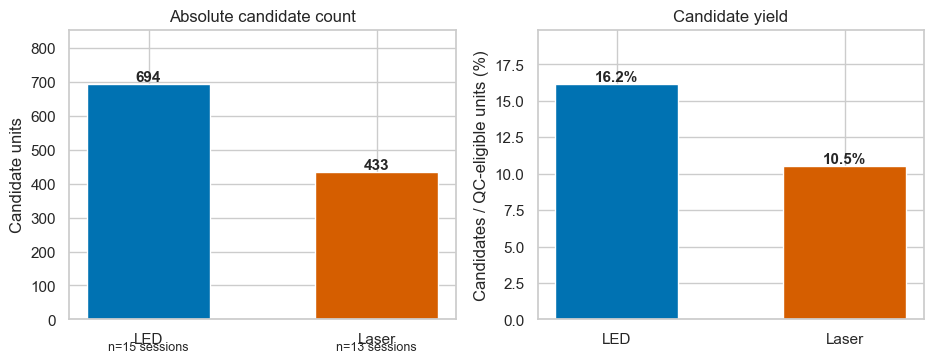

In [2]:
summary = session.groupby("hardware").agg(
    sessions=("ecephys_session_id", "size"),
    eligible=("eligible", "sum"), candidates=("candidates", "sum")).reindex(order)
summary["yield_pct"] = 100 * summary.candidates / summary.eligible
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, col, ylabel in zip(axes, ["candidates", "yield_pct"],
                            ["Candidate units", "Candidates / QC-eligible units (%)"]):
    vals = summary[col].to_numpy()
    ax.bar(order, vals, color=[colors[h] for h in order], width=.54)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.0f}" if col=="candidates" else f"{v:.1f}%",
                ha="center", va="bottom", fontsize=11, weight="bold")
    ax.set(ylabel=ylabel); ax.set_ylim(0, max(vals)*1.23)
axes[0].set_title("Absolute candidate count")
axes[1].set_title("Candidate yield")
for i,h in enumerate(order):
    axes[0].text(i, -max(summary.candidates)*.13, f"n={summary.loc[h,'sessions']} sessions",
                 ha="center", fontsize=9)
fig.tight_layout()
plt.show()

**Evoked firing-rate distributions**
Laser candidates have a higher **median response rate (21.7 Hz)** than LED candidates (**5.6 Hz**) in this analysis. Bars show the percentage of candidates within each hardware group in a rate range. The highest rate bin is open-ended; this is a response-strength comparison, not a tagging-validity test.

In [ ]:
bins = [0, 10, 25, 50, 100, np.inf]
labels = ["0–10", "10–25", "25–50", "50–100", ">100"]
rate_bins = candidates.assign(rate_bin=pd.cut(candidates.evoked_rate_hz,
                                              bins=bins, labels=labels, right=False))
rate_pct = (pd.crosstab(rate_bins.hardware, rate_bins.rate_bin, normalize="index")
              .reindex(index=order, columns=labels, fill_value=0) * 100)
x = np.arange(len(labels))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4))
for j,h in enumerate(order):
    bars = ax.bar(x + (j-0.5)*width, rate_pct.loc[h], width, label=h, color=colors[h])
ax.set_xticks(x, labels)
ax.set(xlabel="Evoked firing rate (Hz; 8-ms window)",
       ylabel="Percentage of candidates in hardware group",
       title="Candidate response strength by hardware")
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
plt.show()
print("Median evoked rate (Hz) by hardware:")
print(candidates.groupby("hardware").evoked_rate_hz.median().reindex(order).round(2))

**Firing rates vary across sessions**
The session-level Welch comparison of candidate mean rates was **LED − laser = −32.83 Hz (95% CI −47.00 to −18.67; p ≈ 0.00025)** in the original run. Show each session rather than treating 1,127 units as independent experiments. Statistical significance does not establish hardware causation.

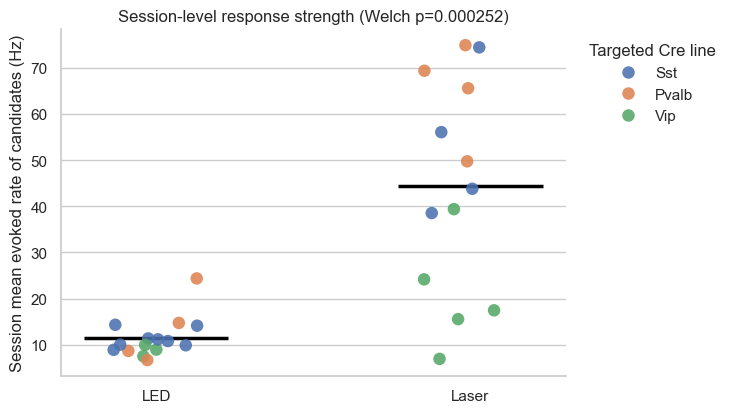

Sessions: LED=15, laser=13; mean difference LED - laser=-32.83 Hz.
Interpret cautiously: hardware coincides with recording era, stimulation protocol, and session composition.


In [4]:
s = session.dropna(subset=["mean_evoked_hz"]).copy()
a = s.loc[s.hardware.eq("LED"), "mean_evoked_hz"].to_numpy()
b = s.loc[s.hardware.eq("Laser"), "mean_evoked_hz"].to_numpy()
test = stats.ttest_ind(a, b, equal_var=False)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
sns.stripplot(data=s, x="hardware", y="mean_evoked_hz", hue="cre_line",
              order=order, jitter=.15, size=9, alpha=.88, ax=ax)
for i, h in enumerate(order):
    sub=s.loc[s.hardware.eq(h), "mean_evoked_hz"]
    ax.hlines(sub.mean(), i-.23, i+.23, color="black", linewidth=2.5)
ax.set(xlabel="", ylabel="Session mean evoked rate of candidates (Hz)",
       title=f"Session-level response strength (Welch p={test.pvalue:.3g})")
ax.legend(title="Targeted Cre line", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
fig.tight_layout()
plt.show()
print(f"Sessions: LED={len(a)}, laser={len(b)}; mean difference LED - laser={a.mean()-b.mean():.2f} Hz.")
print("Interpret cautiously: hardware coincides with recording era, stimulation protocol, and session composition.")

**Austin's plot — one evoked spike, zero baseline**
The left panel reproduces the exact observation: **261/694 LED candidates (37.6%)** had **one total evoked spike and zero baseline spikes**, versus **0/433 laser candidates**. **Caution:** the zero for laser is forced by the candidate threshold interacting with the larger pulse count (45 LED pulses versus mostly 75 laser pulses). The right panel uses a more comparable exploratory rate criterion (**≤0.1 mean evoked spike/pulse**): **72.6% LED versus 38.8% laser**. Neither panel validates a hardware exclusion decision.

In [ ]:
WINDOW_S = 0.008
# Counts are reconstructed from aggregate rates and presentation counts.
# The original processing uses 8-ms baseline and evoked windows.
candidates = candidates.copy()
candidates["evoked_total"] = np.rint(candidates.evoked_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["baseline_total"] = np.rint(candidates.baseline_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["exact_one_zero"] = (candidates.evoked_total == 1) & (candidates.baseline_total == 0)
candidates["mean_spikes_per_pulse"] = candidates.evoked_rate_hz * WINDOW_S
THRESH = 0.10  # Exploratory, NOT a validated candidate exclusion criterion
candidates["weak_per_pulse"] = candidates.mean_spikes_per_pulse <= THRESH

def summarize(flag):
    result = candidates.groupby("hardware").agg(
        total=("unit_id", "size"), matching=(flag, "sum")).reindex(order)
    result["pct"] = 100 * result.matching / result.total
    return result
exact = summarize("exact_one_zero")
comparable = summarize("weak_per_pulse")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)
panels = [
    ("Exactly 1 evoked spike, 0 baseline spikes", exact),
    ("≤0.1 mean evoked spike / pulse", comparable)
]
for ax, (ttl, dat) in zip(axes, panels):
    ax.bar(order, dat.pct, width=.55, color=[colors[h] for h in order])
    for j,h in enumerate(order):
        row = dat.loc[h]
        ax.text(j, row.pct + 2, f"{row.pct:.1f}%\n({int(row.matching)}/{int(row.total)})",
                ha="center", va="bottom", fontsize=10, weight="bold")
    ax.set(title=ttl, xlabel="", ylim=(0, 100))
axes[0].set_ylabel("Percentage of candidates within hardware group")
fig.suptitle("Austin's question: how common are weak optotagging responses?", fontsize=12)
fig.tight_layout()
plt.show()
print("Exact one-evoked/zero-baseline counts (pulse-count-dependent):")
print(exact.round(1))
print("\nExploratory comparable mean-spikes-per-pulse cutoff:")
print(comparable.round(1))
print("\nIMPORTANT: For a unit with baseline=0, one total spike passes the >2 ratio")
print("at 45 pulses (2.78 Hz), but not at 75 pulses (1.67 Hz).")
print("Thus laser=0 in the left panel is structurally enforced by candidate selection.")

**Interpretation for Liz and Austin**
LED yielded a greater proportion of QC-eligible candidate units, while laser-period candidates showed stronger evoked responses. Austin's exact one-spike/zero-baseline pattern is common in LED **because the selection rule allows it there but not in the longer laser protocols**. The normalized weak-response comparison also favors stronger laser responses, but is an exploratory threshold. **Do not exclude either hardware group yet**: verify the session-to-hardware mapping and examine pulse-resolved reliability, optical power, genotype, and recording-period confounds before making a biological or quality-control decision.